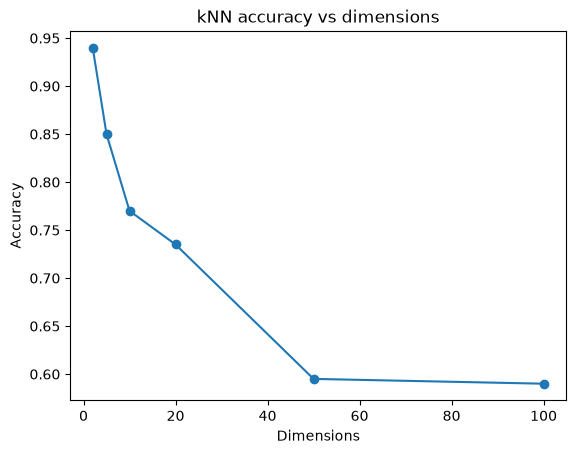

contrast: 0.36073335888774793
[0.7853981633974483, 0.5235987755982988, 0.00032599188692738996]


In [1]:
# ===================== REVISION / ONE-SHOT: CURSE OF DIMENSIONALITY =====================
import numpy as np
import matplotlib.pyplot as plt
from math import gamma, pi
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1) kNN accuracy as dimensions grow (only 2 useful features, rest are noise)
dims, accs = [2, 5, 10, 20, 50, 100], []
for d in dims:
    X, y = make_classification(n_samples=1000, n_features=d, n_informative=2, n_redundant=0, random_state=42)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    sc = StandardScaler().fit(X_train)
    model = KNeighborsClassifier(n_neighbors=5).fit(sc.transform(X_train), y_train)
    accs.append(accuracy_score(y_test, model.predict(sc.transform(X_test))))
plt.plot(dims, accs, marker="o"); plt.title("kNN accuracy vs dimensions"); plt.xlabel("Dimensions"); plt.ylabel("Accuracy"); plt.show()

# 2) Distance concentration: (max - min) / min distance shrinks with dimension
X = np.random.rand(500, 100)
d = np.linalg.norm(X - X[0], axis=1)[1:]
print("contrast:", (d.max() - d.min()) / d.min())

# 3) Volume of unit-diameter ball inside unit cube -> goes to 0
print([pi ** (n / 2) * 0.5 ** n / gamma(n / 2 + 1) for n in (2, 3, 12)])

# ---------------- VIVA NOTES ----------------
# Volume grows as r^d: points needed for same density grow exponentially (500 in 3D -> 500^4 in 12D).
# In high D all points are almost equally far apart, so nearest-neighbour ideas lose meaning.
# Data becomes sparse -> overfitting, more samples needed, more compute and memory.
# Fixes: feature selection, PCA/LDA, regularization, more data.
# kNN suffers most (distance based); SVM with margin + regularization copes better.
# Read plot: accuracy falling as noisy dimensions are added = curse of dimensionality.

### Q28

Write a Python program that demonstrates the curse of dimensionality using the k-Nearest Neighbors (k-NN) classifier with k=5. The program should create a synthetic dataset with varying dimensions and evaluate the performance of the k-NN classifier as the number of dimensions increases. Specifically, you should:
- Generate a synthetic dataset with a fixed number of samples (e.g., 1000) and varying dimensions (e.g., 2, 5, 10, 20, 50, 100).
- Use the k-NN classifier to classify the data.
- Measure and print the accuracy of the classifier for each dimensionality.

Visualize the accuracy as a function of dimensionality.

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [3]:
# 1000 samples; only 2 informative features, extra dimensions are noise
dims = [2, 5, 10, 20, 50, 100]
accs = []
for d in dims:
    X, y = make_classification(n_samples=1000, n_features=d, n_informative=2,
                               n_redundant=0, random_state=42)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    sc = StandardScaler()
    X_train = sc.fit_transform(X_train)
    X_test = sc.transform(X_test)
    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accs.append(accuracy_score(y_test, y_pred))
    print(f"Dimensions = {d:3d} -> accuracy = {accs[-1]:.3f}")

Dimensions =   2 -> accuracy = 0.940
Dimensions =   5 -> accuracy = 0.850
Dimensions =  10 -> accuracy = 0.770
Dimensions =  20 -> accuracy = 0.735
Dimensions =  50 -> accuracy = 0.595
Dimensions = 100 -> accuracy = 0.590


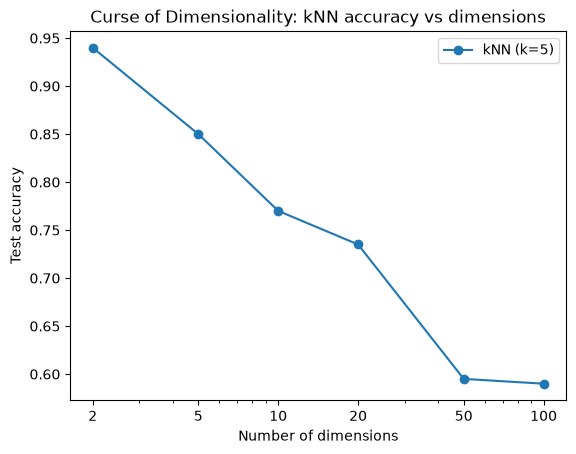

In [4]:
plt.plot(dims, accs, marker="o", label="kNN (k=5)")
plt.title("Curse of Dimensionality: kNN accuracy vs dimensions")
plt.xlabel("Number of dimensions")
plt.ylabel("Test accuracy")
plt.xscale("log")
plt.xticks(dims, dims)
plt.legend()
plt.show()

### Q29

You are using a Support Vector Machine (SVM) classifier for a dataset that has 3 features and 500 data points.

If you increase the dimensionality from 3 features to 12 features, explain how the volume of the feature space changes. What are the potential challenges that arise from this increase in dimensionality?

Instructions:
- Provide detailed answers to both questions, incorporating concepts from machine learning and geometry.
- Use diagrams or examples where appropriate to illustrate your points.

Discuss the implications of high-dimensional spaces on model performance, including overfitting, computational complexity, and the curse of dimensionality.

**Answer**

**1. How the volume changes (geometry)**
- If every feature ranges over length r, the feature space is a hypercube with volume V = r^d.
- 3 features: V = r^3. 12 features: V = r^12. So the volume grows by a factor of r^9 (with r = 10: 10^3 = 1,000 vs 10^12, a billion times bigger).
- Same 500 points now fill a far bigger space. In 3D, 500 points is about 500^(1/3) ≈ 7.9 points per axis. To keep that same density in 12D you need 7.9^12 = 500^4 ≈ 6.25 x 10^10 points.
- Most of the volume moves to the corners and edges: a ball that touches all sides of the unit cube fills 52% of it in 3D but only about 0.03% in 12D.
- Distances concentrate: the nearest and the farthest neighbour become almost equally far away, so "close" and "far" lose meaning.

**2. Challenges for the SVM and the model in general**
- **Data sparsity:** 500 points in 12D leave most regions empty, so the decision boundary is based on very little local evidence.
- **Overfitting:** more dimensions give more freedom. A linear SVM in d dimensions can shatter d + 1 points (VC dimension), and an RBF kernel can fit noise. Training accuracy rises while test accuracy falls. Control it with a smaller C, a tuned gamma, and cross-validation.
- **Irrelevant or noisy features:** extra features add noise to every distance and dot product, which hurts kernels (RBF uses distances).
- **Computational cost:** each kernel evaluation costs O(d), and training is about O(n^2 d) to O(n^3), with more memory needed and slower tuning (grid search).
- **Harder to visualize and interpret:** you cannot plot 12D, and feature interactions are hard to explain.
- **Curse of dimensionality:** the amount of data needed for reliable generalization grows exponentially with d.

**3. Remedies**
- Feature selection, PCA or LDA to reduce dimensions.
- Regularization (C in SVM), scaling the features, and cross-validation.
- Collect more data.
- SVMs are relatively robust because they depend on the margin and the support vectors, not directly on d. They still need tuning when n is small compared with d.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from math import gamma, pi

In [6]:
# Demo 1: volume of the space and points needed for the same density
r = 10                                  # each feature ranges over 0..10
for d in [3, 12]:
    print(f"d = {d:2d}: volume = r^d = {r ** d:,}")
pts_per_axis = 500 ** (1 / 3)
print(f"Points per axis in 3D: {pts_per_axis:.2f}")
print(f"Points needed in 12D for same density: {pts_per_axis ** 12:,.0f}")

d =  3: volume = r^d = 1,000
d = 12: volume = r^d = 1,000,000,000,000
Points per axis in 3D: 7.94
Points needed in 12D for same density: 62,500,000,000


d =  2: ball covers 78.5398% of the cube
d =  3: ball covers 52.3599% of the cube
d = 12: ball covers 0.0326% of the cube


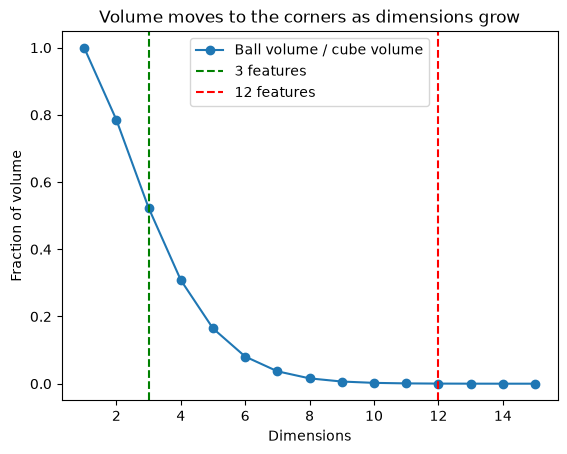

In [7]:
# Demo 2: fraction of unit cube covered by inscribed ball (radius 0.5)
dims = np.arange(1, 16)
ball = [pi ** (d / 2) * 0.5 ** d / gamma(d / 2 + 1) for d in dims]
for d in [2, 3, 12]:
    print(f"d = {d:2d}: ball covers {100 * ball[d - 1]:.4f}% of the cube")
plt.plot(dims, ball, marker="o", label="Ball volume / cube volume")
plt.axvline(3, color="green", linestyle="--", label="3 features")
plt.axvline(12, color="red", linestyle="--", label="12 features")
plt.title("Volume moves to the corners as dimensions grow")
plt.xlabel("Dimensions")
plt.ylabel("Fraction of volume")
plt.legend()
plt.show()

d =   1: (max - min) / min distance = 8529.492
d =   2: (max - min) / min distance = 105.451
d =   3: (max - min) / min distance = 7.749
d =   5: (max - min) / min distance = 6.575
d =  12: (max - min) / min distance = 2.091
d =  50: (max - min) / min distance = 0.678
d = 100: (max - min) / min distance = 0.365
d = 500: (max - min) / min distance = 0.151


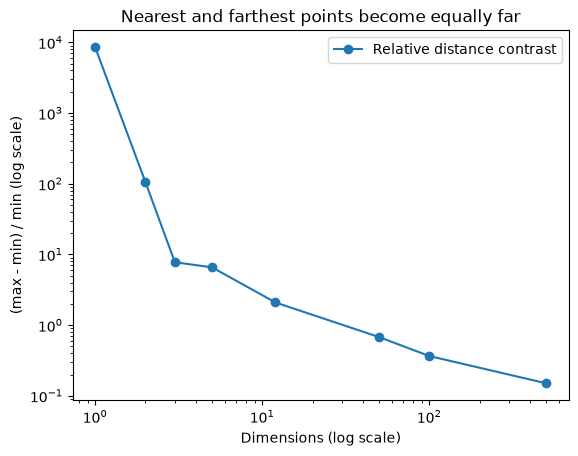

In [8]:
# Demo 3: distance concentration with 500 random points
np.random.seed(42)
contrast = []
dims = [1, 2, 3, 5, 12, 50, 100, 500]
for d in dims:
    X = np.random.rand(500, d)
    dist = np.linalg.norm(X[1:] - X[0], axis=1)        # distances from point 0
    contrast.append((dist.max() - dist.min()) / dist.min())
    print(f"d = {d:3d}: (max - min) / min distance = {contrast[-1]:.3f}")
plt.plot(dims, contrast, marker="o", label="Relative distance contrast")
plt.xscale("log")
plt.yscale("log")
plt.title("Nearest and farthest points become equally far")
plt.xlabel("Dimensions (log scale)")
plt.ylabel("(max - min) / min (log scale)")
plt.legend()
plt.show()